In [2]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

R = 15.0       # радиус детектора
N = 2000       # число ФЭУ
r = 0.1        # радиус чувствительной области ФЭУ
a = 0.5        # квантовая эффективность

In [3]:
def generate_positions(N, R):
    k = np.arange(N)
    z = 1 - 2 * (k + 0.5) / N
    phi = k * np.pi * (3 - np.sqrt(5))
    rho = np.sqrt(1 - z**2)
    return R * np.column_stack((rho * np.cos(phi), rho * np.sin(phi), z))

In [4]:
pmts = generate_positions(N, R)
assert pmts.shape == (N, 3)
assert np.allclose(np.linalg.norm(pmts, axis=1), R)

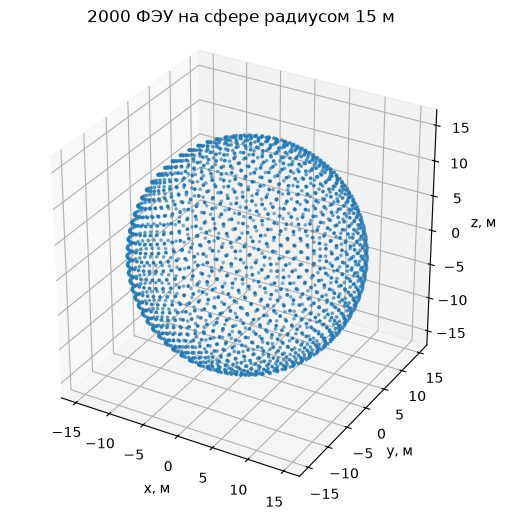

In [5]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*pmts.T, s=3)
ax.set(xlabel="x, м", ylabel="y, м", zlabel="z, м", title="2000 ФЭУ на сфере радиусом 15 м")
ax.set_box_aspect((1, 1, 1))
plt.show()

In [6]:
def hits_bruteforce(points, pmts, r):
    counts = np.zeros(len(pmts), dtype=int)
    for p in points:
        distances_sq = np.sum((pmts - p)**2, axis=1)
        j = int(np.argmin(distances_sq))
        if distances_sq[j] <= r**2:
            counts[j] += 1
    return counts

In [7]:
h = 0.3

def key_of(point, h):
    return tuple(np.floor(point / h).astype(int))

def build_grid(pmts, h):
    grid = {}  
    for j, point in enumerate(pmts):
        cell = key_of(point, h)
        if cell not in grid:
            grid[cell] = []
        grid[cell].append(j)
    return grid

def hits_grid(points, pmts, r, grid, h):
    counts = np.zeros(len(pmts), dtype=int)
    for point in points:
        x, y, z = key_of(point, h)
        best_j = -1
        best_d2 = r**2
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                for dz in (-1, 0, 1):
                    neighbor = (x + dx, y + dy, z + dz)
                    for j in grid.get(neighbor, []):
                        d2 = np.sum((pmts[j] - point)**2)
                        if d2 <= r**2 and (best_j == -1 or d2 < best_d2 or
                                           (d2 == best_d2 and j < best_j)):
                            best_j = j
                            best_d2 = d2
        if best_j != -1:
            counts[best_j] += 1
    return counts

In [8]:
grid = build_grid(pmts, h)
print('Количество непустых ячеек:', len(grid))

Количество непустых ячеек: 2000


In [9]:
rng = np.random.default_rng(42)

def random_surface_points(n, R, rng):
    directions = rng.normal(size=(n, 3))
    directions /= np.linalg.norm(directions, axis=1)[:, None]
    return R * directions

In [10]:
points = random_surface_points(3000, R, rng)
counts_slow = hits_bruteforce(points, pmts, r)
counts_fast = hits_grid(points, pmts, r, grid, h)

In [11]:
assert np.array_equal(counts_slow, counts_fast)
assert np.array_equal(hits_bruteforce(pmts, pmts, r),
                      hits_grid(pmts, pmts, r, grid, h))
print('Проверка совпадения алгоритмов пройдена')
print('Всего попаданий:', counts_fast.sum())

Проверка совпадения алгоритмов пройдена
Всего попаданий: 67


In [12]:
def benchmark(fn, repeats=5):
    durations = []
    for _ in range(repeats):
        start = perf_counter()
        fn()
        durations.append(perf_counter() - start)
    return np.median(durations)

In [13]:
for n_points in (100, 1000, 3000):
    subset = points[:n_points]
    t_slow = benchmark(lambda: hits_bruteforce(subset, pmts, r))
    t_fast = benchmark(lambda: hits_grid(subset, pmts, r, grid, h))
    print(f"{n_points:4d} точек: полный перебор = {t_slow*1000:.2f} мс; "
          f"ячейки = {t_fast*1000:.2f} мс; ускорение = {t_slow/t_fast:.2f}x")

 100 точек: полный перебор = 9.21 мс; ячейки = 4.35 мс; ускорение = 2.12x
1000 точек: полный перебор = 79.63 мс; ячейки = 29.18 мс; ускорение = 2.73x
3000 точек: полный перебор = 242.64 мс; ячейки = 109.72 мс; ускорение = 2.21x


Алгоритм стал работать быстрее, чем итерирование по полному списку фотоумножителей.